# DACON 236749 V4 결과 분석

**분석 재실행(analysis replay)**: 이 노트북은 기존 Colab 실행 기록을 로컬 CPU에서 읽어 표와 그래프를 다시 만든다. 새 GPU 학습, 가중치 로드, 밀봉 데이터 접근, 대회 제출은 하지 않는다. 저장된 실행 결과는 Drive에서 그대로 열어볼 수 있다. 원래 Colab 학습 노트북의 capture는 `current_cell_may_be_incomplete=true`로 남아 있으며, 이 노트북은 그 학습 노트북을 완료된 것으로 바꾸어 표현하지 않는다. 재실행할 때는 `V4_analysis_replay_bundle.zip`을 로컬 workspace 루트에 풀고 CPU로 실행한다.

## tl;dr

1차 비교에서 P1–P4는 모두 완료됐지만 품질 게이트를 통과한 후보는 없었다. 선택 결과는 G0 유지(`no_candidate_passed`)이며 sealed 평가는 열지 않았다. 새 matched P1/P3 재검증은 같은 초기 가중치·RNG·seed·exposure로 각각 10에포크를 마쳤다. 10에포크의 P3는 P1보다 seen D는 0.0375 높았지만 OOD D와 rank는 같았고 MUSIC EER는 0.012143 높았다. 음성 관련 라벨에 unknown이 남아 있어 5개 헤드의 종합 점수는 `null`이다.

## Context & Methods

### Key Assumptions

- 기준 결과는 동결된 `v4-retry-selection.json`과 P1–P4 terminal receipt이다.
- 에포크 선택은 종합 FILE EER 최소가 아니라 `min(seen D, OOD D)` 순위를 따른다.
- 기존 P1/P3는 공통 초기 RNG 상태를 증명하지 못했으므로 인과 비교에서 제외한다. 새 matched 재검증은 source commit `d2397ad8cc96667e5bc2e4132d86405afe093f4e`의 별도 실행이다.
- matched 재검증은 한 seed에서의 공정한 비교를 제공하지만 CUDA bitwise 동일성은 주장하지 않는다.
- 탐색은 학습 중 music-eligible 1,116행을 사용했다. train+dev 1,286행 full refit은 후보 탈락으로 실행하지 않았다.

In [1]:
from pathlib import Path
import csv, hashlib, json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
EVIDENCE = ROOT / '.omo' / 'evidence'
def load(name): return json.loads((EVIDENCE / name).read_text(encoding='utf-8'))
def digest(path): return hashlib.sha256(path.read_bytes()).hexdigest()
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 10, 'axes.grid': True, 'axes.axisbelow': True})
selection = load('v4-retry-selection.json')
finished = load('v4-retry-finished.json')
status = load('v4-retry-pipeline_status.json')
terminals = {f'P{i}': load(f'v4-retry-P{i}-terminal.json')['result'] for i in range(1, 5)}
matched_contract = load('v4-matched-remedy_contract.json')
matched = load('v4-matched-comparison.json')
assert selection['selected'] == finished['selection']['selected'] == finished['final'] == 'G0'
assert selection['reason'] == finished['selection']['reason'] == 'no_candidate_passed'
assert all(status[name]['status'] == 'completed' for name in ['G0','P1','P2','P3','P4'])
assert matched['matched_complete'] and matched['legacy_gpu_P3_excluded']
assert matched['receipts']['P1']['initial_weights_sha256'] == matched['receipts']['P3']['initial_weights_sha256']
assert matched['receipts']['P1']['seed_rng_sha256'] == matched['receipts']['P3']['seed_rng_sha256']
print('LOCAL_CPU_ANALYSIS_REPLAY: receipts loaded; no training or sealed access')

LOCAL_CPU_ANALYSIS_REPLAY: receipts loaded; no training or sealed access


## Data

### 1. 입력 해시와 G0 정규화

In [2]:
input_names = ['v4-retry-finished.json','v4-retry-selection.json','v4-retry-pipeline_status.json','v4-retry-G0_predictions.raw.csv','v4-retry-G0_predictions.csv','v4-retry-g0-parity.json','v4-retry-live-run.json'] + [f'v4-retry-P{i}-terminal.json' for i in range(1,5)]
input_names += ['v4-matched-recheck-dispatch.json','v4-matched-remedy_contract.json','v4-matched-P1_trial_receipt.json','v4-matched-P3_trial_receipt.json','v4-matched-P1_terminal.json','v4-matched-P3_terminal.json','v4-matched-comparison.json','v4-matched-release_requested.json','v4-matched-drive_receipt.json','v4-matched-notebook_capture.json']
hash_table = pd.DataFrame([{'artifact': n, 'sha256': digest(EVIDENCE/n)} for n in input_names])
raw = list(csv.DictReader((EVIDENCE/'v4-retry-G0_predictions.raw.csv').open(encoding='utf-8-sig')))
normalized = list(csv.DictReader((EVIDENCE/'v4-retry-G0_predictions.csv').open(encoding='utf-8-sig')))
assert len(raw) == len(normalized) == 210
assert raw == normalized
parity = load('v4-retry-g0-parity.json')
print(f'G0 rows=210; semantic raw/normalized equality={raw == normalized}; FILE formula tolerance notes={len(parity)}')
hash_table

G0 rows=210; semantic raw/normalized equality=True; FILE formula tolerance notes=2


,artifact,sha256
0,v4-retry-finished.json,8e95508a2b65010786bb4d11497b48fce1fc885ecdff50...
1,v4-retry-selection.json,6463fea6d16ae58637d2fef2c181ebaaeb8e42b18b01e6...
2,v4-retry-pipeline_status.json,1a7ab63df435ae257513c178eaf4c9a0607f6c20d949ca...
3,v4-retry-G0_predictions.raw.csv,bd1c27227829f36e9ae6191db7600920bf6649810f0896...
4,v4-retry-G0_predictions.csv,ebb664e274311c596660564a721b0afea6a37baa0a2014...
5,v4-retry-g0-parity.json,1f6aa437d72abbb484aba9cde1b42eb820b21a7d8494eb...
6,v4-retry-live-run.json,c79a1c600209a1a5e208a50b8b704e5c5c179f376480eb...
7,v4-retry-P1-terminal.json,bbb2d8b2a06091bddcab033955766b96350b5e8b92f1dc...
8,v4-retry-P2-terminal.json,81cf8452fcafc3c538395aec716d27be3dd53ff250c3f2...
9,v4-retry-P3-terminal.json,47edc3c4193bd3333c45f983409ca7d73d8651cfe06043...


raw와 normalized G0 CSV는 파싱한 210행의 값과 순서가 모두 같다. 바이트 해시 차이는 개행 표현 차이이다. `v4-retry-g0-parity.json`에 남은 2개 행의 최대 차이는 독립적으로 반올림한 head로 FILE을 다시 계산할 때의 5e-11 미만 수치 잔차다.

## Results

### 2. 1차 P1–P4 비교

In [3]:
rows = []
epoch_rows = []
for name, trial in terminals.items():
    selected_epoch = trial['best_epoch']
    selected_report = trial['reports'][selected_epoch - 1]
    minimum_file_report = min(trial['reports'], key=lambda r: (r['evaluation']['absolute']['metrics']['file_eer'], r['epoch']))
    candidate = selection['candidates'][name]
    evaluation = candidate['evaluation']
    rows.append({
        'pipeline': name, 'selected_epoch': selected_epoch,
        'minimum_FILE_epoch': minimum_file_report['epoch'],
        'selected_FILE_EER': evaluation['absolute']['metrics']['file_eer'],
        'selected_MUSIC_EER': evaluation['absolute']['metrics']['music_eer'],
        'seen_D': evaluation['music']['music_seen']['D'],
        'OOD_D': evaluation['music']['music_ood']['D'],
        'rank': evaluation['rank_score'], 'gate_pass': candidate['gates']['passed'],
        'runtime_s': candidate['runtime_seconds'], 'refit_performed': False,
    })
    for report in trial['reports']:
        metrics = report['evaluation']['absolute']['metrics']
        scores = report['evaluation']['music']
        epoch_rows.append({'pipeline': name, 'epoch': report['epoch'], 'FILE_EER': metrics['file_eer'], 'MUSIC_EER': metrics['music_eer'], 'seen_D': scores['music_seen']['D'], 'OOD_D': scores['music_ood']['D']})
comparison = pd.DataFrame(rows)
epochs = pd.DataFrame(epoch_rows)
assert not comparison['gate_pass'].any()
comparison.round(6)

,pipeline,selected_epoch,minimum_FILE_epoch,selected_FILE_EER,selected_MUSIC_EER,seen_D,OOD_D,rank,gate_pass,runtime_s,refit_performed
0,P1,5,3,0.342857,0.341429,0.1095,-0.045,-0.045,False,67.788586,False
1,P2,4,9,0.289286,0.370714,0.1770,-0.045,-0.045,False,398.312631,False
2,P3,5,4,0.353571,0.358571,0.0450,-0.117,-0.117,False,202.850371,False
3,P4,2,5,0.367857,0.446429,0.1095,-0.045,-0.045,False,228.441696,False


`selected_epoch`와 `minimum_FILE_epoch`은 다른 질문에 답한다. 전자는 seen/OOD의 더 낮은 D를 최대화한 에포크고, 후자는 전체 known-label FILE EER만 최소화한 에포크다. 따라서 두 열의 불일치를 오류로 보면 안 된다.

### 3. 에포크별 FILE/MUSIC EER

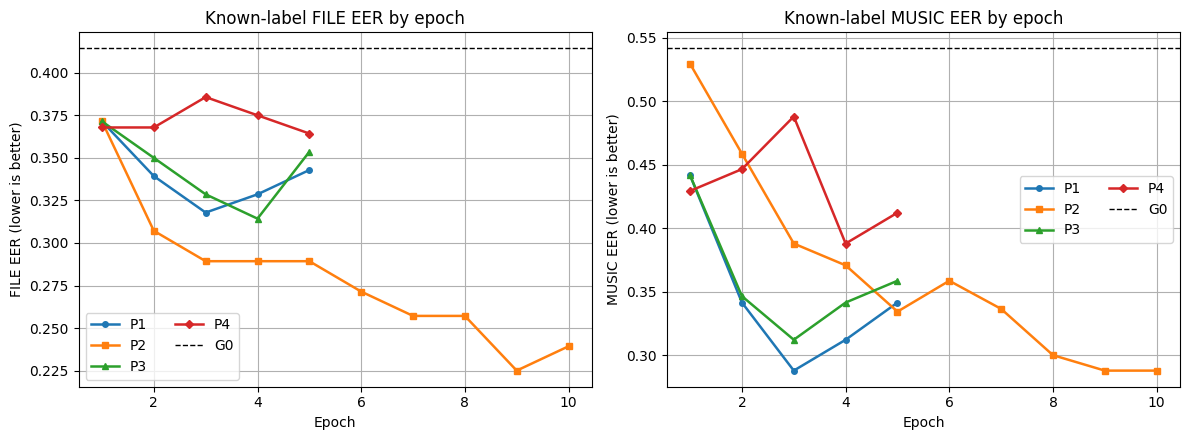

/Users/choiwuseck/Documents/ChatGPT/데이콘/.omo/evidence/v4-results-epoch-eer.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=False)
styles = {'P1':'o-','P2':'s-','P3':'^-','P4':'D-'}
for name, group in epochs.groupby('pipeline'):
    axes[0].plot(group['epoch'], group['FILE_EER'], styles[name], label=name, linewidth=1.8, markersize=4)
    axes[1].plot(group['epoch'], group['MUSIC_EER'], styles[name], label=name, linewidth=1.8, markersize=4)
axes[0].axhline(0.4142857143, color='black', linestyle='--', linewidth=1, label='G0')
axes[1].axhline(0.5414285714, color='black', linestyle='--', linewidth=1, label='G0')
for ax, title, ylabel in zip(axes, ['Known-label FILE EER by epoch', 'Known-label MUSIC EER by epoch'], ['FILE EER (lower is better)', 'MUSIC EER (lower is better)']):
    ax.set(title=title, xlabel='Epoch', ylabel=ylabel); ax.legend(ncol=2)
fig.tight_layout()
eer_plot = EVIDENCE / 'v4-results-epoch-eer.png'
fig.savefig(eer_plot, dpi=170, bbox_inches='tight')
plt.show()
print(eer_plot)

### 4. 선택 에포크의 seen/OOD D

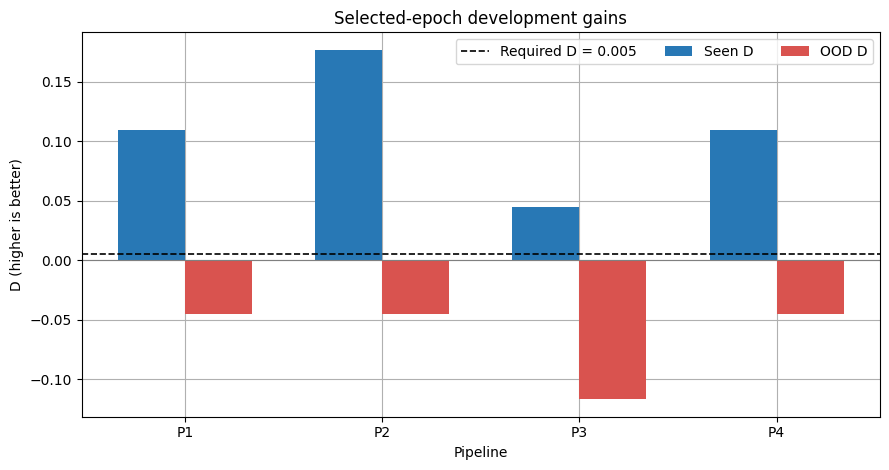

/Users/choiwuseck/Documents/ChatGPT/데이콘/.omo/evidence/v4-results-seen-ood.png


In [5]:
x = np.arange(len(comparison)); width = 0.34
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x-width/2, comparison['seen_D'], width, label='Seen D', color='#2878B5')
ax.bar(x+width/2, comparison['OOD_D'], width, label='OOD D', color='#D9534F')
ax.axhline(0.005, color='black', linestyle='--', linewidth=1.2, label='Required D = 0.005')
ax.axhline(0, color='gray', linewidth=.8)
ax.set(title='Selected-epoch development gains', xlabel='Pipeline', ylabel='D (higher is better)', xticks=x, xticklabels=comparison['pipeline'])
ax.legend(ncol=3); fig.tight_layout()
score_plot = EVIDENCE / 'v4-results-seen-ood.png'
fig.savefig(score_plot, dpi=170, bbox_inches='tight')
plt.show()
print(score_plot)

P1, P2, P4는 선택 에포크에서 OOD D=-0.045였고 P3는 -0.117이었다. 모두 요구치 0.005에 미달했으며, 통계 게이트까지 포함한 최종 품질 게이트를 통과한 후보는 없다.

### 5. 새 matched P1/P3 재검증

In [6]:
matched_rows, matched_epochs = [], []
for name in ['P1', 'P3']:
    trial = matched[name]
    selected = trial['reports'][trial['best_epoch'] - 1]
    minimum_file = min(trial['reports'], key=lambda r: (r['evaluation']['absolute']['metrics']['file_eer'], r['epoch']))
    evaluation = selected['evaluation']; metrics = evaluation['absolute']['metrics']
    matched_rows.append({'pipeline': name, 'completed_epochs': trial['epochs_completed'], 'total_updates': trial['run_total_updates'], 'selected_epoch': trial['best_epoch'], 'selected_update': trial['updates'], 'minimum_FILE_epoch': minimum_file['epoch'], 'FILE_EER': metrics['file_eer'], 'MUSIC_EER': metrics['music_eer'], 'seen_D': evaluation['music']['music_seen']['D'], 'OOD_D': evaluation['music']['music_ood']['D'], 'rank': evaluation['rank_score'], 'runtime_s': trial['seconds']})
    for report in trial['reports']:
        e=report['evaluation']; m=e['absolute']['metrics']
        matched_epochs.append({'pipeline':name,'epoch':report['epoch'],'FILE_EER':m['file_eer'],'MUSIC_EER':m['music_eer'],'seen_D':e['music']['music_seen']['D'],'OOD_D':e['music']['music_ood']['D'],'rank':e['rank_score']})
matched_table=pd.DataFrame(matched_rows); matched_epoch_table=pd.DataFrame(matched_epochs)
assert set(matched_table['completed_epochs']) == {10} and set(matched_table['total_updates']) == {350}
matched_table.round(6)

,pipeline,completed_epochs,total_updates,selected_epoch,selected_update,minimum_FILE_epoch,FILE_EER,MUSIC_EER,seen_D,OOD_D,rank,runtime_s
0,P1,10,350,6,210,2,0.371429,0.387857,0.0675,-0.045,-0.045,127.961532
1,P3,10,350,8,280,10,0.335714,0.341429,0.0495,-0.045,-0.045,383.178321


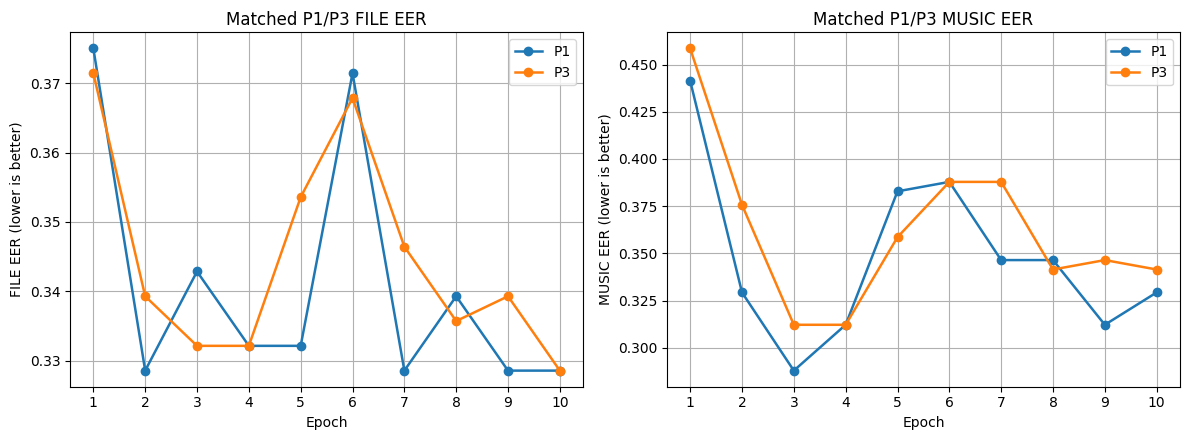

/Users/choiwuseck/Documents/ChatGPT/데이콘/.omo/evidence/v4-results-matched-eer.png


In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for name, group in matched_epoch_table.groupby('pipeline'):
    axes[0].plot(group.epoch,group.FILE_EER,'o-',label=name,linewidth=1.8)
    axes[1].plot(group.epoch,group.MUSIC_EER,'o-',label=name,linewidth=1.8)
for ax,title,ylabel in zip(axes,['Matched P1/P3 FILE EER','Matched P1/P3 MUSIC EER'],['FILE EER (lower is better)','MUSIC EER (lower is better)']):
    ax.set(title=title,xlabel='Epoch',ylabel=ylabel,xticks=range(1,11));ax.legend()
fig.tight_layout(); matched_eer_plot=EVIDENCE/'v4-results-matched-eer.png';fig.savefig(matched_eer_plot,dpi=170,bbox_inches='tight');plt.show();print(matched_eer_plot)

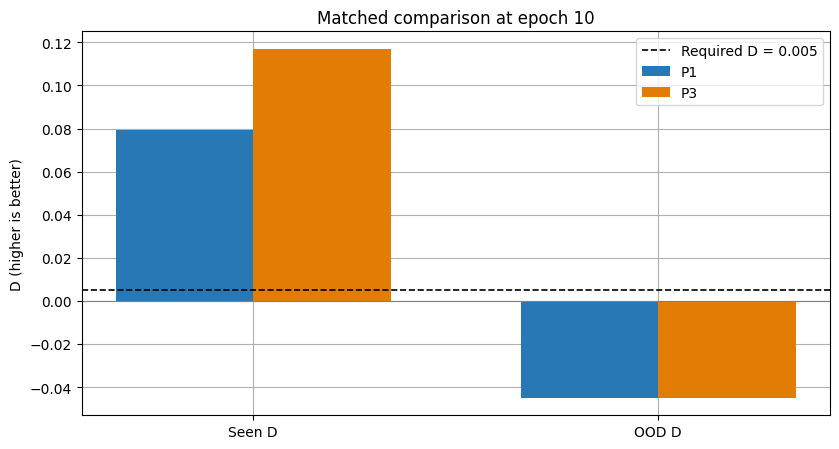

,FILE_EER,MUSIC_EER,seen_D,OOD_D,rank
P3_minus_P1,0.0,0.012143,0.0375,0.0,0.0


/Users/choiwuseck/Documents/ChatGPT/데이콘/.omo/evidence/v4-results-matched-gain.png


In [8]:
epoch10=matched_epoch_table[matched_epoch_table.epoch==10].set_index('pipeline')
delta=(epoch10.loc['P3',['FILE_EER','MUSIC_EER','seen_D','OOD_D','rank']]-epoch10.loc['P1',['FILE_EER','MUSIC_EER','seen_D','OOD_D','rank']]).rename('P3_minus_P1')
fig,ax=plt.subplots(figsize=(8.5,4.6));x=np.arange(2);width=.34
for offset,name,color in [(-width/2,'P1','#2878B5'),(width/2,'P3','#E17C05')]:
    values=epoch10.loc[name,['seen_D','OOD_D']];ax.bar(x+offset,values,width,label=name,color=color)
ax.axhline(.005,color='black',linestyle='--',linewidth=1.2,label='Required D = 0.005');ax.axhline(0,color='gray',linewidth=.8)
ax.set(title='Matched comparison at epoch 10',ylabel='D (higher is better)',xticks=x,xticklabels=['Seen D','OOD D']);ax.legend();fig.tight_layout()
matched_gain_plot=EVIDENCE/'v4-results-matched-gain.png';fig.savefig(matched_gain_plot,dpi=170,bbox_inches='tight');plt.show();display(delta.to_frame().T.round(6));print(matched_gain_plot)

두 arm은 각각 10에포크·350업데이트·11,160 window exposure를 마쳤다. 선택 checkpoint는 P1 에포크 6, P3 에포크 8이며, 전체 실행 업데이트 350개와 각각 210개·280개인 선택 checkpoint update를 구분해야 한다. 같은 에포크 10에서 P3-P1은 FILE EER 0.000000, MUSIC EER +0.012143, seen D +0.037500, OOD D 0.000000, rank 0.000000이다. 이 한 seed 결과는 P3의 전반적 우위를 입증하지 않는다.

## Takeaways

- 1차 실행의 안전한 결론은 G0 유지다. `sealed=false`이며 full refit도 실행하지 않았다.
- 전체 FILE/MUSIC EER만으로 후보를 고르면 OOD 실패를 놓칠 수 있다.
- 기존 P1/P3 차이는 인과 비교에서 제외했다. 새 matched 실행은 공통 초기 가중치·RNG·seed와 같은 exposure를 기록했지만, 한 seed의 결과며 CUDA bitwise 동일성은 주장하지 않는다.
- matched 재검증은 분석 자료일 뿐 기존 G0 선택을 자동으로 바꾸지 않는다. 공식 종합 점수도 새로 계산할 수 없다.
- 이 문서는 로컬 CPU 분석 재실행이며 새로운 학습 성과를 만들지 않는다.